# Bước 6A — Che nhân tạo có kiểm soát và thiết kế pilot B1/B2
**Đồ án CV nâng cao · Nhóm A/B/C · Codex tiếp nối Claude bước 5 · 05/11/2026**

Mục tiêu là tạo một can thiệp có thể kiểm: cùng ảnh nền và ngân sách, B1 không thêm che; B2 thêm một vùng che với xác suất 50%. DigiFace vốn có mũ/kính/góc khó, nên **B1 là dữ liệu nền**, không gọi là ảnh rõ.

Notebook chứa thuật toán, tạo manifest thật, kiểm mask/seed/leakage và hình từ ảnh nguồn. Chưa train ở đây. Notebook pilot kế tiếp đọc cấu hình và manifest này, nhưng có code augmentation/training/evaluator cốt lõi ngay trong notebook đó để người đọc theo dõi được.

## 1. Câu hỏi, phạm vi và cách chạy

1. Che vùng nào, bao nhiêu pixel, có lặp lại được từ ID/seed không?
2. Ảnh biến thể có kế thừa identity/partition/group, gallery có bị sửa không?
3. B1/B2 có thực sự nhìn cùng số ảnh nền và cùng số bước không?

Chạy kernel mới theo thứ tự. Raw chỉ đọc. Test/ROF/MFR2 không được mở ảnh hoặc đưa vào tuning; chính sách test được định nghĩa trước nhưng chưa materialize biến thể. Tất cả hình minh họa ở đây lấy từ train.

In [1]:
from pathlib import Path
from datetime import datetime,timezone
from concurrent.futures import ThreadPoolExecutor
import hashlib,json,os,time,platform
import numpy as np
import pandas as pd
from PIL import Image,ImageOps
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

def find_root():
    options=[Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    options += [Path.cwd(),*Path.cwd().parents]
    for p in options:
        if (p/'ban_giao_nhom/augmentation/Augmentation_che_co_kiem_soat.ipynb').is_file():return p.resolve()
    raise FileNotFoundError('Mở trong bản tiếp nối bước6 hoặc đặt CV_PROJECT_ROOT')
ROOT=find_root();HERE=ROOT/'ban_giao_nhom/augmentation';OUT=HERE/'notebook_outputs'
TAB,FIG,MASKS=OUT/'tables',OUT/'figures',OUT/'example_masks'
for p in [OUT,TAB,FIG,MASKS]:p.mkdir(parents=True,exist_ok=True)
START=time.perf_counter()
ROLE=ROOT/'ban_giao_nhom/protocol/notebook_outputs/tables/05_image_roles_draft.csv'
DECISIONS=ROOT/'ban_giao_nhom/quyet_dinh_nhom/input/project_decisions.csv'
def sha(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(2**20),b''):h.update(b)
    return h.hexdigest()
def digest(x):return hashlib.sha256(json.dumps(x,sort_keys=True,ensure_ascii=False).encode()).hexdigest()
def save(d,name):d.to_csv(TAB/(name+'.csv'),index=False,encoding='utf-8-sig',float_format='%.17g');return d
def jwrite(x,name):(OUT/name).write_text(json.dumps(x,ensure_ascii=False,indent=2),encoding='utf-8')
def stable(xs,context):return sorted(set(xs),key=lambda x:(digest([20261105,context,x]),x))
def vn(x,d=0):return f'{x:,.{d}f}'.replace(',','_').replace('.',',').replace('_','.')
def finish(fig,name):
    for ext in ['png','svg']:fig.savefig(FIG/(name+'.'+ext),bbox_inches='tight',dpi=160)
    display(fig);plt.close(fig)
plt.rcParams.update({'font.family':'Arial','figure.dpi':110,'axes.unicode_minus':False})
R=pd.read_csv(ROLE,dtype=str,keep_default_na=False)
decisions=pd.read_csv(DECISIONS,dtype=str,keep_default_na=False)
assert dict(zip(decisions.decision_id,decisions.chosen_option))=={
    'P1':'conservative_withhold','P2':'base_gallery_3','P3':'external_test_only',
    'P4':'fpir_05_empirical','P5':'direct_resize_digiface'}
INPUT_HASH={'roles':sha(ROLE),'decisions':sha(DECISIONS)}
display(R.groupby(['partition','role']).agg(images=('image_id','size'),identities=('canonical_identity','nunique')))

images  identities
partition role                             
test      gallery           300         100
          known_query      3700         100
          unknown_query    4000         100
train     train           57600        1600
          train_monitor    6400        1600
val       gallery           300         100
          known_query      3700         100
          unknown_query    4000         100

## 2. Chốt can thiệp trước train

Che hình chữ nhật tại vùng mắt, dưới, trái hoặc phải trên khung 160×160; bbox có jitter ±4 pixel, màu xám lấy ngẫu nhiên độc lập với danh tính. Đây là vùng ảnh theo tọa độ tương đối, **không phải xác minh vùng giải phẫu**, không mô phỏng khẩu trang thật.

Mask nhị phân 1 là pixel được thay; tỷ lệ = số pixel mask / 25.600 pixel **toàn khung**. Tất cả spec có seed, bbox, màu và ID biến thể. Ảnh không thêm che có mask rỗng và bytes pixel giống ảnh nền.

Xác suất 50% áp dụng cho mỗi lượt ảnh train B2. Mỗi lượt vẫn chỉ cho một tensor, không nhân đôi dataset hoặc optimizer steps. B1 dùng cùng thứ tự ảnh và không thêm can thiệp nào khác.

In [2]:
AUG={'version':'rectangle_occlusion_v1','seed':20261105,'size':160,
     'train_probability':0.5,'kinds':['eyes','lower','left','right'],
     'boxes':{'eyes':[8,36,152,82],'lower':[12,82,148,144],
              'left':[4,16,56,144],'right':[104,16,156,144]},
     'jitter_pixels':4,'fill_values':[32,96,160,224],
     'area_denominator':'whole_160x160_frame_not_face_area',
     'normalization_after_augmentation':'(pixel_0_255 - 127.5)/128 exactly once',
     'val_policy':'one_fixed_forced_occlusion_per_query; gallery_unchanged',
     'test_policy':'same_predeclared_algorithm; materialize_only_after_final_config_lock'}
PILOT={'version':'pilot_128ids_v1','seed':20261105,'identities':128,'batch_size':32,
       'head_warmup_epochs':1,'fine_tune_epochs':2,'full_training_claimed':False,
       'checkpoint_selection':'max_base_validation_DIR_at_FPIR05; tie:occluded_DIR_at_base_threshold; tie:earlier_epoch',
       'encoder_open_layers':['block8','last_linear','last_bn'],
       'bn_running_stats':'frozen_all_layers','dropout':'train_only_during_encoder_fine_tune',
       'optimizer':'AdamW','lr_head':0.001,'lr_encoder':0.00003,'weight_decay':0.0001,
       'gradient_clip_norm':5.0,'amp':False,'evaluation_batch_size':256}
display(pd.DataFrame([{'field':k,'value':str(v)} for k,v in AUG.items()]))

,field,value
0,version,rectangle_occlusion_v1
1,seed,20261105
2,size,160
3,train_probability,0.5
4,kinds,"['eyes', 'lower', 'left', 'right']"
5,boxes,"{'eyes': [8, 36, 152, 82], 'lower': [12, 82, 1..."
6,jitter_pixels,4
7,fill_values,"[32, 96, 160, 224]"
8,area_denominator,whole_160x160_frame_not_face_area
9,normalization_after_augmentation,(pixel_0_255 - 127.5)/128 exactly once


In [3]:
def make_spec(image_id, epoch, partition, force=False):
    seed=int(hashlib.sha256(f"{AUG['seed']}|{partition}|{epoch}|{image_id}".encode()).hexdigest()[:16],16)
    rng=np.random.default_rng(seed)
    applied=bool(force or rng.random()<AUG['train_probability'])
    kind=AUG['kinds'][int(rng.integers(len(AUG['kinds'])))] if applied else 'none'
    box=[0,0,0,0];fill=0
    if applied:
        box=np.array(AUG['boxes'][kind],dtype=int)+rng.integers(-4,5,size=4)
        box=np.clip(box,0,160).tolist()
        fill=int(rng.choice(AUG['fill_values']))
    area=max(0,box[2]-box[0])*max(0,box[3]-box[1])
    return {'image_id':image_id,'epoch':int(epoch),'partition':partition,'seed':str(seed),
            'applied':applied,'kind':kind,'x1':box[0],'y1':box[1],'x2':box[2],'y2':box[3],
            'fill_gray':fill,'mask_pixels':area,'frame_pixels':160*160,
            'mask_fraction_frame':area/(160*160),
            'variant_id':'VAR_'+hashlib.sha256(f'{image_id}|{seed}|{kind}|{box}|{fill}'.encode()).hexdigest()[:24]}

def apply_spec(pixels,spec):
    if pixels.dtype!=np.uint8 or pixels.shape!=(160,160,3):raise ValueError('Expected uint8 RGB160')
    mask=np.zeros((160,160),dtype=np.uint8)
    if bool(spec['applied']):mask[int(spec['y1']):int(spec['y2']),int(spec['x1']):int(spec['x2'])]=1
    if int(mask.sum())!=int(spec['mask_pixels']):raise ValueError('Mask area does not match metadata')
    result=pixels.copy();result[mask.astype(bool)]=int(spec['fill_gray'])
    return result,mask

## 3. Chọn subset pilot theo danh tính, giữ nguyên validation

Pilot chọn 128/1.600 danh tính train bằng thứ tự hash seed cố định. Mỗi người có 36 ảnh train và 4 monitor. Monitor chỉ đo overfit trên người đã học; validation 200 người mới giữ nguyên 8.000 ảnh theo bước 5.

Quy mô này kiểm được training và chi phí thực, chưa đủ để kết luận B1/B2 cuối cùng trên 1.600 người. Full train cần quyết định ngân sách dựa trên thời gian đo ở pilot, không suy từ tên GPU.

In [4]:
train_ids=stable(R[R.partition.eq('train')].canonical_identity,'pilot_training_identities')[:PILOT['identities']]
T=R[R.canonical_identity.isin(train_ids)&R.role.eq('train')].sort_values('image_id').reset_index(drop=True)
M=R[R.canonical_identity.isin(train_ids)&R.role.eq('train_monitor')].sort_values('image_id').reset_index(drop=True)
V=R[R.partition.eq('val')].sort_values('image_id').reset_index(drop=True)
Q=V[V.role.isin(['known_query','unknown_query'])].copy()
assert len(T)==128*36 and len(M)==128*4 and len(V)==8000
assert not set(T.canonical_identity)&set(V.canonical_identity)
for col in ['image_id','sha256','pixel_sha256','photo_group','leakage_group','guard_group']:
    assert not set(T[col])&set(M[col]),'Train/monitor leakage: '+col
    assert not set(pd.concat([T,M])[col])&set(V[col]),'Train/val leakage: '+col
for frame,name in [(T,'01_pilot_train'),(M,'01_pilot_monitor'),(V,'01_validation_roles')]:save(frame,name)
label_map={x:i for i,x in enumerate(sorted(train_ids))}
assert set(label_map.values())==set(range(len(label_map)))
jwrite(label_map,'label_mapping.json')
display(pd.DataFrame([{'scope':'pilot_train','images':len(T),'identities':T.canonical_identity.nunique()},
                     {'scope':'pilot_monitor','images':len(M),'identities':M.canonical_identity.nunique()},
                     {'scope':'validation','images':len(V),'identities':V.canonical_identity.nunique()}]))

,scope,images,identities
0,pilot_train,4608,128
1,pilot_monitor,512,128
2,validation,8000,200


## 4. Tạo manifest biến thể train và validation thật

Mọi biến thể có `base_image_id`, hash raw, identity, partition, role và guard group từ ảnh nền. Train có spec cho từng epoch; validation query có đúng một spec cố định, gallery không bị che. Test chưa có ảnh/tensor biến thể được tạo.

Checkpoint được chọn bằng chỉ số chính đã có: DIR trên validation nền tại FPIR 5%. Robustness là phép đo bổ sung trên **cùng query** có che, dùng nguyên threshold đã hiệu chỉnh trên ảnh nền; không điều chỉnh threshold cho từng kiểu che.

In [5]:
rows=[];epochs=PILOT['head_warmup_epochs']+PILOT['fine_tune_epochs']
for epoch in range(epochs):
    for r in T.itertuples():
        rows.append({**make_spec(r.image_id,epoch,'train'),
            'base_image_id':r.image_id,'source_sha256':r.sha256,'canonical_identity':r.canonical_identity,
            'role':'train','guard_group':r.guard_group})
TS=save(pd.DataFrame(rows),'02_B2_train_variant_specs')
VS=save(pd.DataFrame([{**make_spec(r.image_id,-1,'val',force=True),
    'base_image_id':r.image_id,'source_sha256':r.sha256,'canonical_identity':r.canonical_identity,
    'role':r.role,'guard_group':r.guard_group} for r in Q.itertuples()]),'02_validation_query_variant_specs')
assert TS.groupby('epoch').size().eq(len(T)).all() and TS.variant_id.is_unique
assert VS.image_id.is_unique and set(VS.image_id)==set(Q.image_id)
assert not set(VS.image_id)&set(V[V.role.eq('gallery')].image_id)
assert TS[TS.applied].mask_fraction_frame.between(.15,.4).all()
assert TS[~TS.applied].mask_pixels.eq(0).all()
assert VS.mask_fraction_frame.between(.15,.4).all()
assert not TS.partition.isin(['test','external_test_reserve']).any()
actual=save(TS.groupby(['epoch','kind']).agg(images=('image_id','size'),
    median_area=('mask_fraction_frame','median')).reset_index(),'03_train_augmentation_counts')
display(actual)
display(VS.groupby(['role','kind']).size().rename('queries').unstack(fill_value=0))

,epoch,kind,images,median_area
0,0,eyes,563,0.258750
1,0,left,576,0.258789
2,0,lower,590,0.330469
3,0,none,2269,0.000000
4,0,right,610,0.259883
5,1,eyes,579,0.258750
6,1,left,595,0.260000
7,1,lower,565,0.327305
8,1,none,2266,0.000000
9,1,right,603,0.259453


kind,eyes,left,lower,right
role,,,,
known_query,939,939,937,885
unknown_query,1013,977,1003,1007


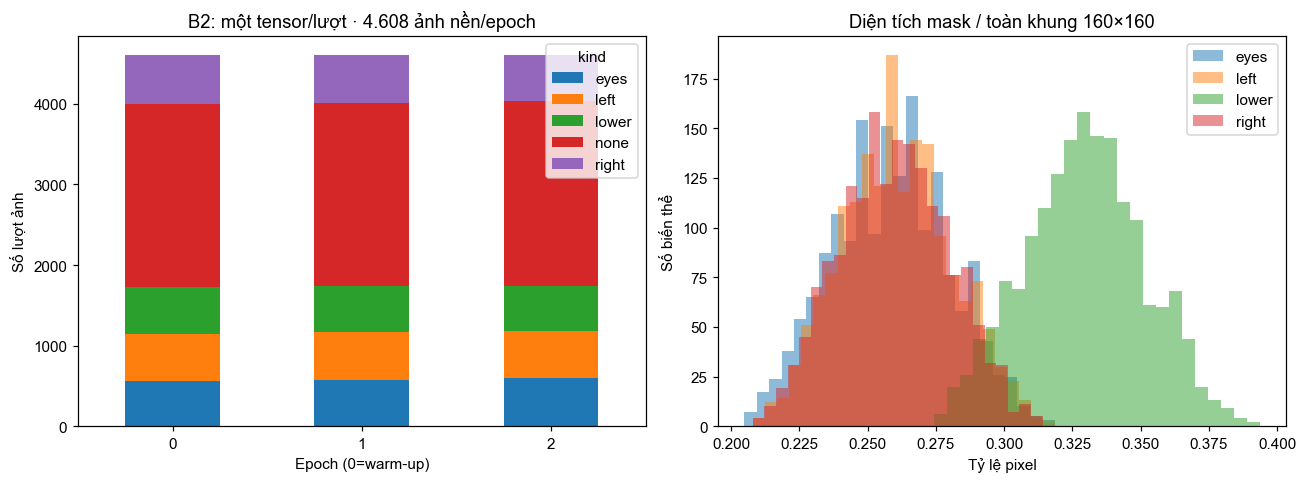

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
pd.crosstab(TS.epoch,TS.kind).plot.bar(stacked=True,ax=axes[0],rot=0)
axes[0].set(title=f'B2: một tensor/lượt · {vn(len(T))} ảnh nền/epoch',ylabel='Số lượt ảnh',xlabel='Epoch (0=warm-up)')
for kind,g in TS[TS.applied].groupby('kind'):
    axes[1].hist(g.mask_fraction_frame,bins=25,alpha=.5,label=kind)
axes[1].set(title='Diện tích mask / toàn khung 160×160',xlabel='Tỷ lệ pixel',ylabel='Số biến thể')
axes[1].legend();fig.tight_layout();finish(fig,'03_probability_and_area')

## 5. Kiểm tính tất định, tính đúng mask và các ca cố tình làm sai

Kiểm trên tất cả spec train: cùng ID/epoch/seed phải sinh cùng metadata và mask, pixel ngoài mask không đổi, số pixel thay thế trùng mẫu số. Đổi seed/epoch phải tạo được biến thể khác. Kiểm RGB/uint8 diễn ra trước standardization.

Các ca sai chỉ nằm trong RAM. Bắt lỗi diện tích/bounds/dtype giúp tránh một mask hiển thị khác với mask dùng khi train.

In [7]:
synthetic_pixels=np.arange(160*160*3,dtype=np.uint32).reshape(160,160,3).astype(np.uint8)
mask_checks=0
for r in TS.itertuples():
    spec=make_spec(r.image_id,r.epoch,'train')
    assert spec['variant_id']==r.variant_id
    out,mask=apply_spec(synthetic_pixels,spec)
    assert set(np.unique(mask))<={0,1}
    assert np.array_equal(out[mask==0],synthetic_pixels[mask==0])
    if spec['applied']:assert (out[mask==1]==spec['fill_gray']).all()
    else:assert np.array_equal(out,synthetic_pixels)
    mask_checks+=1
assert make_spec(T.image_id.iloc[0],0,'train')!=make_spec(T.image_id.iloc[0],1,'train')
neg=[]
bad=make_spec(T.image_id.iloc[0],0,'train',True);bad['mask_pixels']+=1
for label,pix,spec in [('area mismatch',synthetic_pixels,bad),
                       ('wrong dtype',synthetic_pixels.astype(np.float32),make_spec(T.image_id.iloc[0],0,'train')),
                       ('wrong size',synthetic_pixels[:112,:112],make_spec(T.image_id.iloc[0],0,'train'))]:
    caught=False
    try:apply_spec(pix,spec)
    except ValueError:caught=True
    assert caught;neg.append({'fault':label,'caught':caught})
save(pd.DataFrame(neg),'04_negative_checks')
display(Markdown(f'Đã kiểm **{vn(mask_checks)} spec train**, seed/epoch và **{len(neg)} ca sai**. '
    'Không dùng kết quả model để chọn mask hoặc loại ảnh khó.'))

Đã kiểm **13.824 spec train**, seed/epoch và **3 ca sai**. Không dùng kết quả model để chọn mask hoặc loại ảnh khó.

## 6. Minh họa ảnh nền, ảnh che và mask nhị phân

Chọn bốn ảnh train bằng hash ID. Mỗi hàng là một ảnh nền, bốn kiểu che và một mask; ảnh được hash trước mở. Các mask PNG lưu ở `example_masks/` chỉ là mẫu minh họa, không phải toàn bộ bộ train.

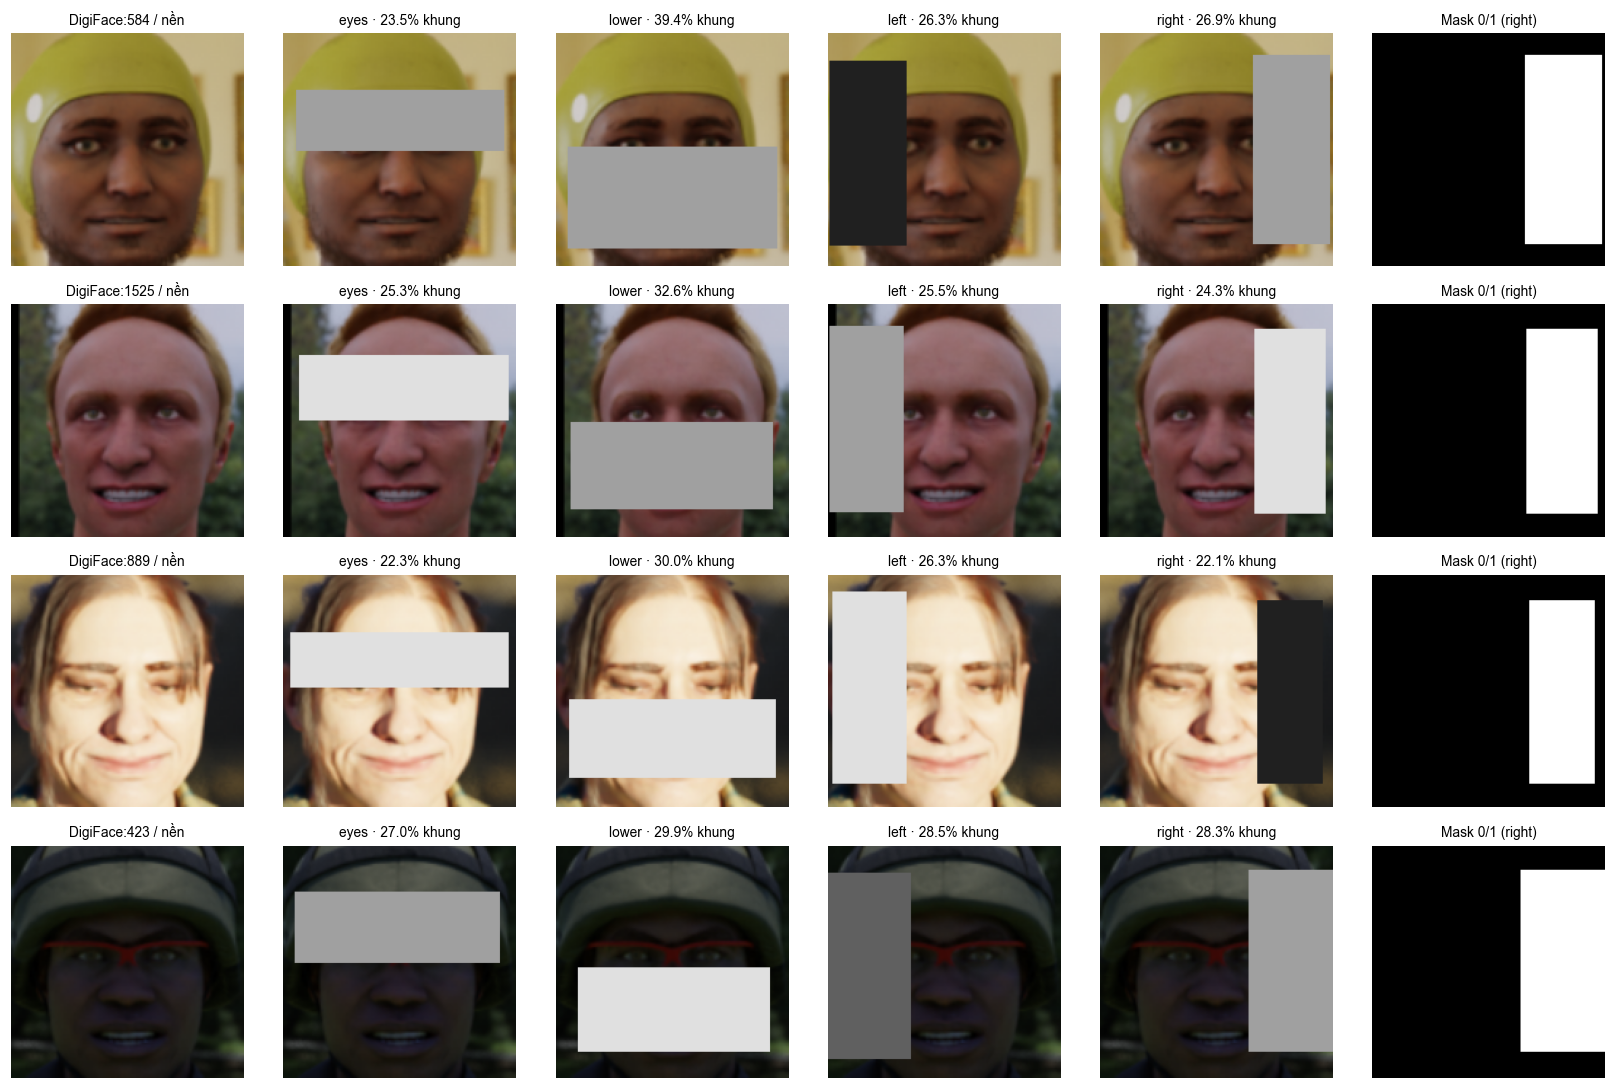

In [8]:
def open_rgb(row):
    p=ROOT/row.path;assert sha(p)==row.sha256,'Raw đổi bytes'
    with Image.open(p) as source:
        im=ImageOps.exif_transpose(source)
        if 'A' in im.getbands():
            rgba=im.convert('RGBA')
            if (np.asarray(rgba.getchannel('A'))<255).any():im=Image.alpha_composite(Image.new('RGBA',rgba.size,(255,255,255,255)),rgba)
        return np.asarray(im.convert('RGB').resize((160,160),Image.Resampling.BILINEAR),dtype=np.uint8).copy()
examples=T[T.image_id.isin(stable(T.image_id,'augmentation_illustrations')[:4])]
fig,axes=plt.subplots(4,6,figsize=(15,10))
opened=[]
for i,r in enumerate(examples.itertuples()):
    pixels=open_rgb(r);opened.append(r.image_id)
    axes[i,0].imshow(pixels);axes[i,0].set_title(r.canonical_identity+' / nền',fontsize=9)
    for j,kind in enumerate(AUG['kinds'],1):
        # Tìm seed epoch chẩn đoán để minh họa đúng kind bằng cùng thuật toán.
        epoch=1000
        while make_spec(r.image_id,epoch,'train',True)['kind']!=kind:epoch+=1
        spec=make_spec(r.image_id,epoch,'train',True);out,mask=apply_spec(pixels,spec)
        axes[i,j].imshow(out);axes[i,j].set_title(f'{kind} · {100*spec["mask_fraction_frame"]:.1f}% khung',fontsize=9)
        Image.fromarray(mask*255).save(MASKS/(spec['variant_id']+'.png'))
    axes[i,5].imshow(mask,cmap='gray',vmin=0,vmax=1);axes[i,5].set_title('Mask 0/1 (right)',fontsize=9)
for ax in axes.flat:ax.axis('off')
fig.tight_layout();finish(fig,'05_real_training_examples')

## 7. Hợp đồng bàn giao cho pilot và giới hạn

Pilot có một epoch warm-up classifier khi encoder frozen, rồi hai epoch mở block cuối/projection. Loss classifier/monitor chỉ đo khả năng fit người train; đánh giá người mới dùng embedding 512 chiều, bỏ classifier, cùng evaluator bước 5.

Các vùng che chỉ là synthetic rectangles, chưa chứng minh tổng quát sang khẩu trang/kính thật. Ngân sách pilot một seed/128 người không phải thí nghiệm cuối và không thay train trên 1.600 người. Test giữ ngoài tuning; không dùng kết quả test để chỉnh hình che.

In [9]:
nb=json.loads((HERE/'Augmentation_che_co_kiem_soat.ipynb').read_text(encoding='utf-8'))
common_cell=next(''.join(c['source']) for c in nb['cells'] if c['cell_type']=='code' and ''.join(c['source']).startswith('def make_spec'))
implementation_sha=hashlib.sha256(common_cell.encode()).hexdigest()
config={'augmentation':AUG,'pilot':PILOT,'implementation_sha256':implementation_sha,
        'input_sha256':INPUT_HASH,'label_mapping_sha256':sha(OUT/'label_mapping.json'),
        'train_spec_sha256':sha(TAB/'02_B2_train_variant_specs.csv'),
        'validation_spec_sha256':sha(TAB/'02_validation_query_variant_specs.csv'),
        'test_materialized':False,'external_used':False,'version':'step6_augmentation_pilot_contract_v1'}
jwrite(config,'augmentation_pilot_contract.json')
assert sha(ROLE)==INPUT_HASH['roles'] and sha(DECISIONS)==INPUT_HASH['decisions']
summary={'checks':'PASS','train_identities':len(train_ids),'train_images':len(T),'monitor_images':len(M),
    'validation_images':len(V),'train_epoch_specs':len(TS),'validation_occluded_queries':len(VS),
    'specs_checked':mask_checks,'negative_checks':len(neg),'raw_examples_hashed_now':len(opened),
    'raw_modified':False,'test_pixels_used':False,'external_used':False,'training_started':False,
    'contract_sha256':sha(OUT/'augmentation_pilot_contract.json'),
    'executed_at_utc':datetime.now(timezone.utc).isoformat(),'elapsed_seconds':round(time.perf_counter()-START,3)}
jwrite(summary,'execution_summary.json')
display(Markdown(f'**Sẵn sàng pilot:** {vn(len(T))} train + {vn(len(M))} monitor, '
    f'{vn(len(V))} validation; {vn(len(TS))} lượt spec B2 và {vn(len(VS))} query che cố định. '
    'B1/B2 cùng một số lượt ảnh, nguồn và seed. Test/ảnh thật chưa dùng.'))

**Sẵn sàng pilot:** 4.608 train + 512 monitor, 8.000 validation; 13.824 lượt spec B2 và 7.700 query che cố định. B1/B2 cùng một số lượt ảnh, nguồn và seed. Test/ảnh thật chưa dùng.

## 8. Nguồn và đầu ra

- `augmentation_pilot_contract.json`: can thiệp, seed, cấu hình pilot và hash thuật toán.
- `tables/01_*`: danh sách cohort; `02_*`: spec train/query; `03_*`: phân bố thực.
- `example_masks/`, `figures/`: mask thật và hình cho slide.
- `execution_summary.json`: phạm vi tính mới; không tuyên bố đã train.

Tham khảo kỹ thuật fine-tune bằng classifier tạm: [facenet-pytorch example](https://github.com/timesler/facenet-pytorch/blob/master/examples/finetune.ipynb). Protocol người mới và group split dùng thiết kế đồ án, không sao chép random-image split của ví dụ. Giới hạn tái lập giữa phần cứng/phiên bản: [PyTorch 2.2 reproducibility](https://docs.pytorch.org/docs/2.2/notes/randomness.html).